In [ ]:
import pandas as pd

adult_census = pd.read_csv("C:/Users/angel_bothra.sias24_/Downloads/adult/adult.data")

adult_census.head()
print(adult_census.shape)


(32560, 15)


In [ ]:
from sklearn.datasets import fetch_openml
adult = fetch_openml("adult", version = 2, as_frame = True)
x = adult.data
y = adult.target

print(x.head())
x.shape
x.columns


   age  workclass  fnlwgt     education  education-num      marital-status  \
0   25    Private  226802          11th              7       Never-married   
1   38    Private   89814       HS-grad              9  Married-civ-spouse   
2   28  Local-gov  336951    Assoc-acdm             12  Married-civ-spouse   
3   44    Private  160323  Some-college             10  Married-civ-spouse   
4   18        NaN  103497  Some-college             10       Never-married   

          occupation relationship   race     sex  capital-gain  capital-loss  \
0  Machine-op-inspct    Own-child  Black    Male             0             0   
1    Farming-fishing      Husband  White    Male             0             0   
2    Protective-serv      Husband  White    Male             0             0   
3  Machine-op-inspct      Husband  Black    Male          7688             0   
4                NaN    Own-child  White  Female             0             0   

   hours-per-week native-country  
0              

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country'],
      dtype='object')

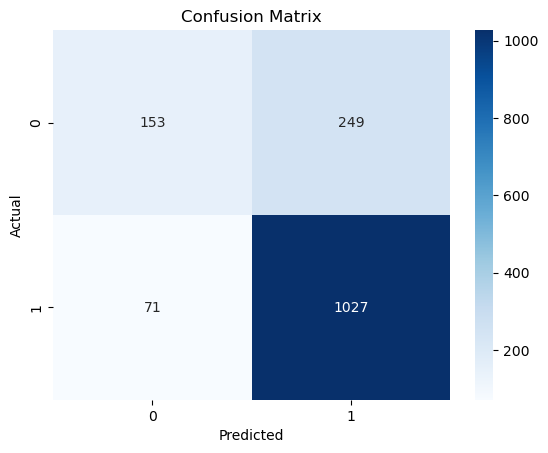

In [ ]:
# age, education-num, capital gain, capital loss,
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
import pandas as pd

# Define column names for Adult dataset
columns = ['age', 'workclass', 'fnlwgt', 'education', 'education-num',
           'marital-status', 'occupation', 'relationship', 'race', 'sex',
           'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

# Load dataset with headers
df = pd.read_csv("C:/Users/angel_bothra.sias24_/Downloads/adult.data",
                 header=None, names=columns)

df = df.iloc[:5000, :]

# Drop missing values
df.dropna(inplace=True)

# Encode target (income) and sex
df['income'] = df['income'].apply(lambda x: 1 if x.strip() == '<=50K' else 0)
df['sex'] = df['sex'].apply(lambda x: 1 if x.strip() == 'Male' else 0)

# Use numeric features + sex
X = df[['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'sex']]
y = df['income']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train logistic regression
clf = LogisticRegression(max_iter=500)
clf.fit(X_train, y_train)

# Predictions
y_pred = clf.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


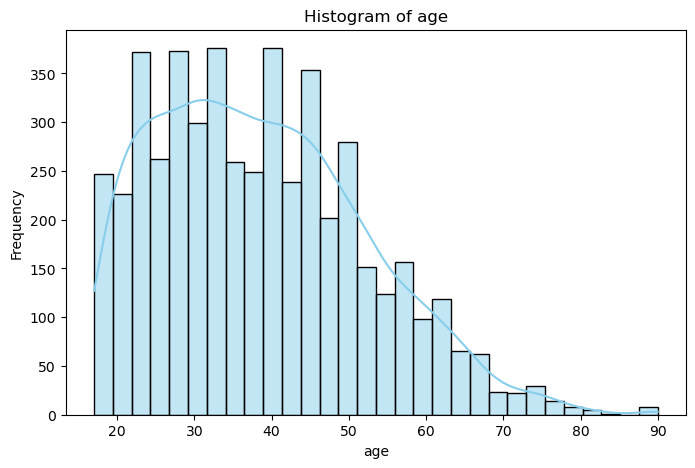

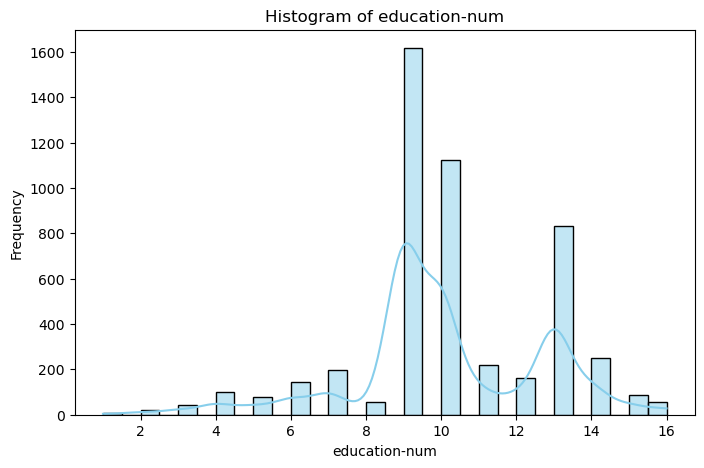

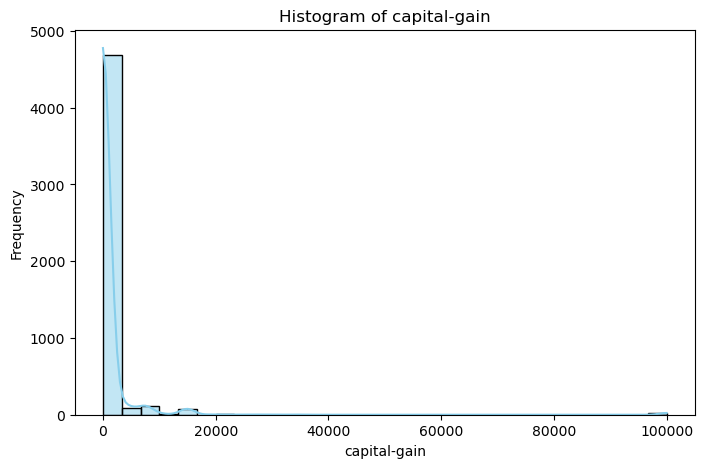

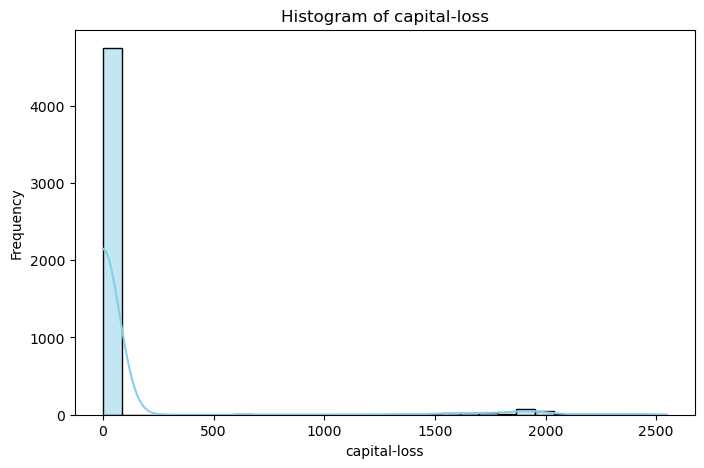

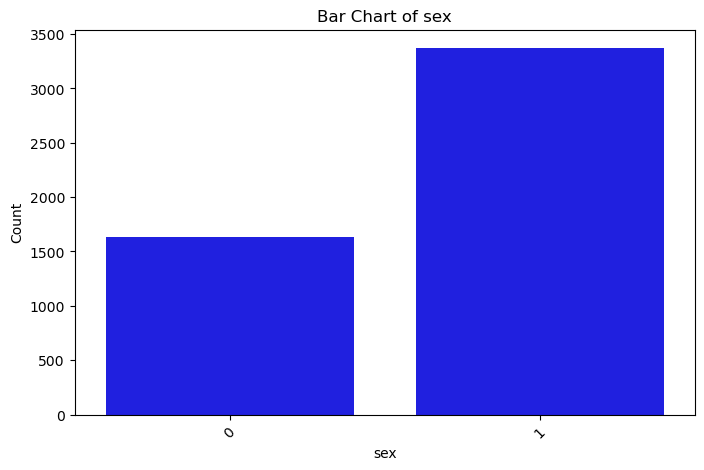

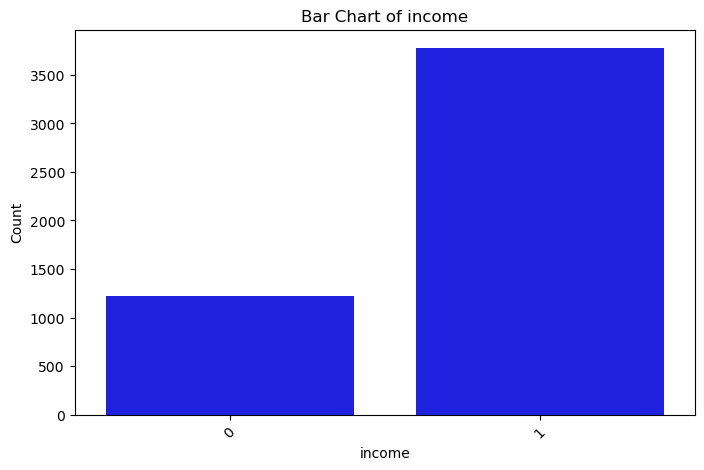

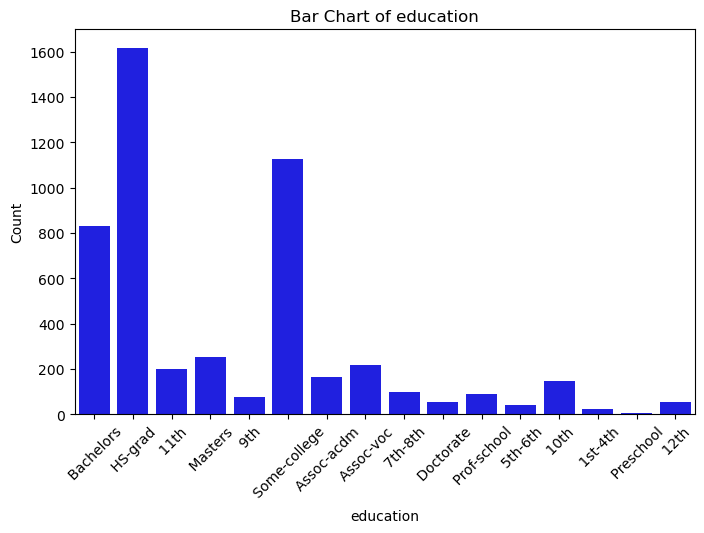

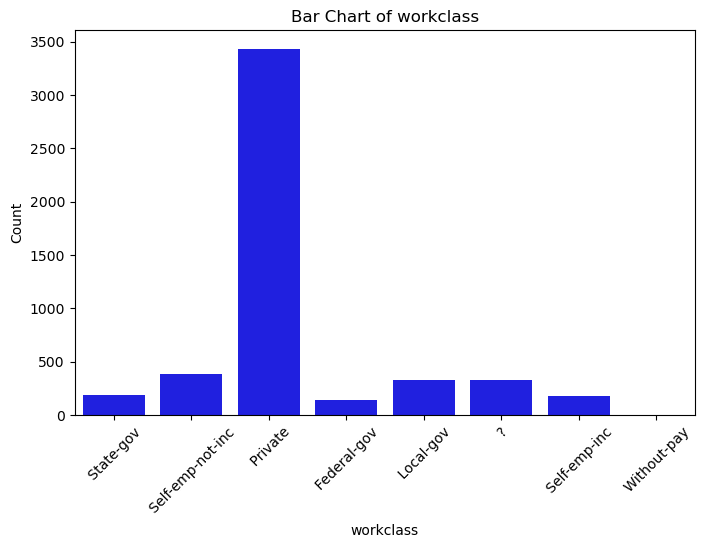

In [ ]:
# Continuous variables - Histograms
continuous_vars = ['age', 'education-num', 'capital-gain', 'capital-loss']

for col in continuous_vars:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], bins=30, kde=True, color='skyblue')
    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

# Discrete variables - Bar charts
discrete_vars = ['sex', 'income', 'education', 'workclass']

for col in discrete_vars:
    plt.figure(figsize=(8, 5))
    sns.countplot(x=col, data=df, color="blue")
    plt.title(f"Bar Chart of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()


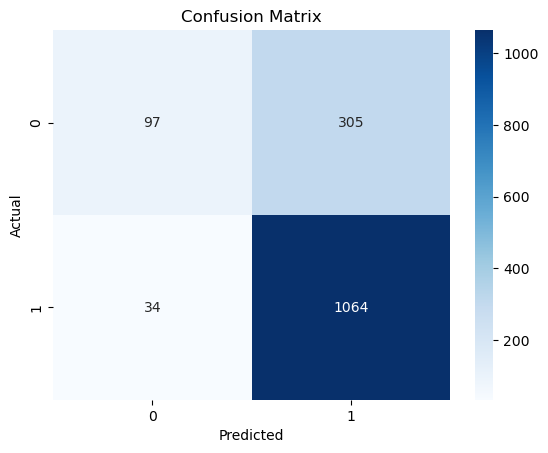

[[  97  305]
 [  34 1064]]
              precision    recall  f1-score   support

           0       0.74      0.24      0.36       402
           1       0.78      0.97      0.86      1098

    accuracy                           0.77      1500
   macro avg       0.76      0.61      0.61      1500
weighted avg       0.77      0.77      0.73      1500



In [ ]:
X = pd.get_dummies(df.drop('income', axis = 1), drop_first = True)
y = df['income']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train logistic regression
clf = LogisticRegression(max_iter=500, solver = 'liblinear')
clf.fit(X_train, y_train)

# Predictions
y_pred = clf.predict(X_test)
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

In [ ]:
# confusion matrix by gender
sex_test = X_test['sex'].values
df_eval = pd.DataFrame({'true' : y_test, 'pred' : y_pred, 'sex' : sex_test})
for label, group in [('female', 0), ('Male', 1)]:
        subset = df_eval[df_eval['sex'] == group]
        cm = confusion_matrix(subset['true'], subset['pred'])
        print(f'|nConfusion Matrix for {label}:')
        print(cm)


|nConfusion Matrix for female:
[[ 24  43]
 [ 11 386]]
|nConfusion Matrix for Male:
[[ 73 262]
 [ 23 678]]
